# Quickstart: unstructured-grid access with DWD ICON-EU icosahedral - dynamical.org Icechunk Zarr

Dynamical.org's unstructured-grid datasets use a one-dimensional `cell` dimension, with `latitude` and `longitude` coordinates on the data and UGRID topology in the `mesh/` group. These examples progress from point selection to mesh-based operations using common Python libraries. Try the patterns you use and tell us which steps feel awkward.

We use `temperature_2m` from the forecast initialized on 10 November 2026 at 00 UTC; maps and means use the 12-hour lead.

Dataset documentation: https://dynamical.org/catalog/dwd-icon-eu-forecast-5-day-icosahedral/

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog 'xarray>=2026.2' matplotlib cartopy geopandas shapely scipy 'uxarray>=2026.10.1' 'xugrid>=0.15.3'

In [2]:
# In staging for feedback, structure may change in breaking ways before promotion to prod.
import os
os.environ.setdefault("DYNAMICAL_STAC_CATALOG_URL", "https://stac-staging.dynamical.org/catalog.json")

import dynamical_catalog

ds = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", chunks=None)
ds

<xarray.Dataset> Size: 945GB
Dimensions:                                             (init_time: 174,
                                                         lead_time: 93,
                                                         cell: 768608)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 129kB ...
  * cell                                                (cell) int32 3MB 0 .....
    latitude                                            (cell) float32 3MB ...
    longitude                                           (cell) float32 3MB ...
    spatial_ref                                         int64 8B ...
Data variables: (12/19)
    cloud_cover_high                                    (init_time, lead_time, cell) float32 50GB ...
    cloud_cover_low                                     (init_time, lead_time, cell) float32 50GB ...
    dew_point_temperature_2m                            (init_time, lead_time, cell) float32 50GB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time, cell) float32 50GB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time, cell) float32 50GB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time, cell) float32 50GB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time, cell) float32 50GB ...
    wind_u_10m                                          (init_time, lead_time, cell) float32 50GB ...
    pressure_reduced_to_mean_sea_level                  (init_time, lead_time, cell) float32 50GB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time, cell) float32 50GB ...
    wind_gust_10m                                       (init_time, lead_time, cell) float32 50GB ...
    wind_v_10m                                          (init_time, lead_time, cell) float32 50GB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

### 1. Select a point — xarray

Create an `NDPointIndex` from the cell centres, then select the nearest centre to Lisbon. The default index measures distance in latitude/longitude degrees; this can choose a different cell from the nearest by great-circle distance.

In [3]:
import xarray as xr

ds = ds.set_xindex(("latitude", "longitude"), xr.indexes.NDPointIndex)
point = ds["temperature_2m"].sel(init_time="2026-11-10T00", lead_time="12h").sel(
    latitude=38.72, longitude=-9.14, method="nearest"
).load()
point

<xarray.DataArray 'temperature_2m' ()> Size: 4B
array(19.375, dtype=float32)
Coordinates:
    cell                      int32 4B 481037
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
    lead_time                 timedelta64[us] 8B 12:00:00
    latitude                  float32 4B 38.73
    longitude                 float32 4B -9.114
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 2. Select several points and plot time series — xarray

Latitude and longitude arrays sharing a `station` dimension request paired locations in one `.sel()` call. Assign the station names back to the result to label Lisbon, Porto and Faro in a 48-hour forecast plot.

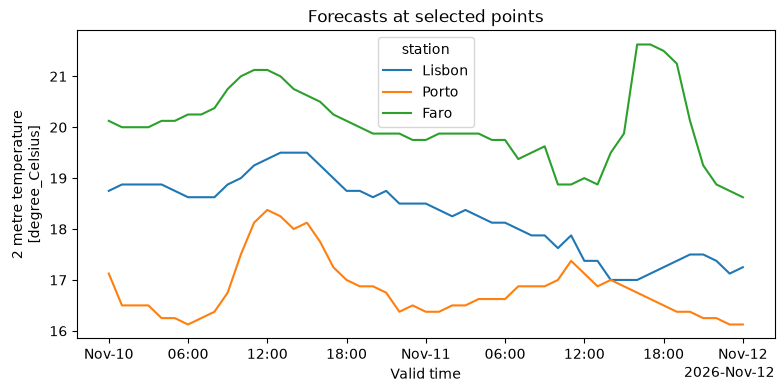

In [4]:
import matplotlib.pyplot as plt
import numpy as np

stations = xr.Dataset(coords={
    "station": ["Lisbon", "Porto", "Faro"],
    "latitude": ("station", [38.72, 41.15, 37.02]),
    "longitude": ("station", [-9.14, -8.61, -7.93]),
})
series = (
    ds["temperature_2m"].sel(
        init_time="2026-11-10T00",
        lead_time=slice(np.timedelta64(0, "h"), np.timedelta64(48, "h")),
    )
    .sel(latitude=stations.latitude, longitude=stations.longitude, method="nearest")
    .assign_coords(station=stations.station)
    .load()
)
series.plot.line(x="valid_time", hue="station", figsize=(9, 4))
plt.title("Forecasts at selected points");

### 3. Select a bounding box — xarray

A boolean mask on the centre coordinates selects cells in a box around mainland Portugal. Load one full-domain field here and reuse it for the remaining spatial examples.

In [5]:
field = ds["temperature_2m"].sel(init_time="2026-11-10T00", lead_time="12h").load()
box_cells = (
    (field.longitude >= -10) & (field.longitude <= -6)
    & (field.latitude >= 37) & (field.latitude <= 42.5)
)
box = field.isel(cell=box_cells)
box

<xarray.DataArray 'temperature_2m' (cell: 4718)> Size: 19kB
array([20.375 , 20.25  , 20.375 , ..., 12.625 , 13.5625, 13.1875],
      shape=(4718,), dtype=float32)
Coordinates:
  * cell                      (cell) int32 19kB 411173 411174 ... 512750 512751
    latitude                  (cell) float32 19kB 37.53 37.62 ... 42.04 42.06
    longitude                 (cell) float32 19kB -9.981 -9.94 ... -7.478 -7.543
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
    lead_time                 timedelta64[us] 8B 12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 4. Make a quick map from centres — Matplotlib and Cartopy

`tripcolor` triangulates the selected centres, so an overview needs no mesh. The shading interpolates between centres rather than drawing the native cell polygons.

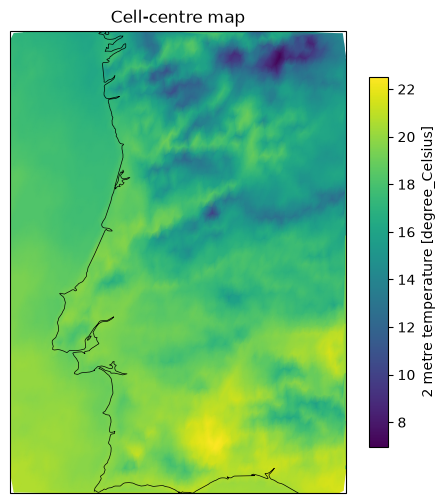

In [6]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": ccrs.PlateCarree()})
image = ax.tripcolor(box.longitude, box.latitude, box, shading="gouraud", cmap="viridis")
ax.coastlines(linewidth=0.5)
ax.set_extent([-10, -6, 37, 42.5])
ax.set_title("Cell-centre map")
fig.colorbar(image, ax=ax, label=f"{box.long_name} [{box.units}]", shrink=0.8);

### 5. Select a polygon and take its mean — GeoPandas, Shapely and xarray

Use Natural Earth's mainland Portugal outline to select cell centres, then average their temperatures. This unweighted mean includes whole cells by their centres; it does not clip cells at the border.

In [7]:
import geopandas as gpd
import shapely
from cartopy.io.shapereader import natural_earth

units = gpd.read_file(natural_earth(resolution="50m", category="cultural", name="admin_0_map_units"))
mainland = units.loc[units.GEOUNIT == "Portugal", "geometry"].iloc[0]
polygon_cells = shapely.contains_xy(mainland, field.longitude.values, field.latitude.values)
polygon = field.isel(cell=polygon_cells)
unweighted = polygon.mean("cell", keep_attrs=True)
unweighted

<xarray.DataArray 'temperature_2m' ()> Size: 4B
array(17.846762, dtype=float32)
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
    lead_time                 timedelta64[us] 8B 12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 6. Regrid to regular latitude/longitude coordinates — xarray

Give target latitude and longitude different dimensions and `NDPointIndex` broadcasts the nearest-neighbour lookup onto a regular grid. Assign the requested coordinates afterward: `.sel()` returns the selected source centres by default.

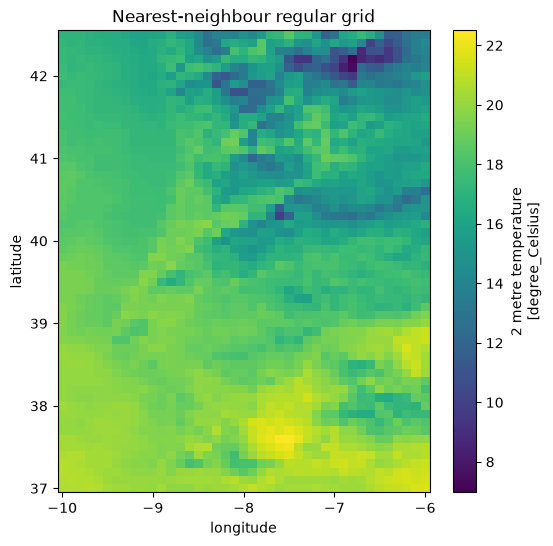

In [8]:
import numpy as np

target = xr.Dataset(coords={
    "latitude": np.arange(37, 42.51, 0.1),
    "longitude": np.arange(-10, -5.99, 0.1),
})
regular = field.sel(latitude=target.latitude, longitude=target.longitude, method="nearest")
regular = regular.assign_coords(target.coords)
regular.plot(x="longitude", y="latitude", figsize=(6, 6), cmap="viridis", center=False)
plt.title("Nearest-neighbour regular grid");

### 7. Open the mesh and draw native polygons — Xugrid

Open the `mesh/` group through the same catalog and attach the field with an explicit Xugrid wrapper. Xugrid needs the `NDPointIndex` dropped first and renumbers cell labels after subsetting.

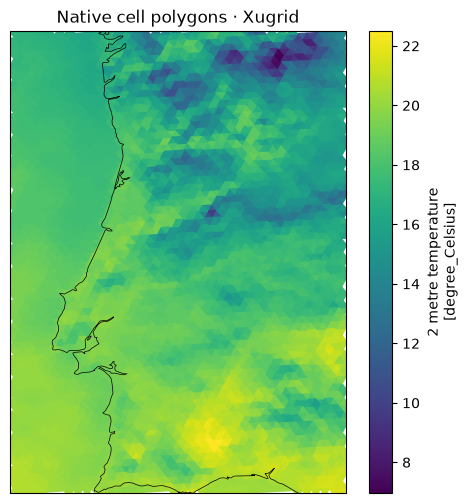

In [9]:
import xugrid as xu

mesh = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", group="mesh", chunks=None)
xgrid = xu.Ugrid2d.from_dataset(mesh)
xfield = xu.UgridDataArray(field.drop_indexes(("latitude", "longitude")), xgrid)
xbox = xfield.isel(cell=np.flatnonzero(box_cells))
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": ccrs.PlateCarree()})
xbox.ugrid.plot(ax=ax, cmap="viridis")
ax.coastlines(linewidth=0.5)
ax.set_extent([-10, -6, 37, 42.5])
ax.set_title("Native cell polygons · Xugrid");

### 8. Compute cell areas and an area-weighted mean — UXarray and xarray

There is no stored `cell_area`, so compute spherical areas from the mesh, translate `n_face` back to `cell`, and attach the original cell labels. UXarray's areas are on a unit sphere; a 6,371 km radius converts them to km², while the weighted mean uses the same centre-selected polygon as above.

In [10]:
import uxarray as ux

uxgrid = ux.open_grid(mesh)
area = uxgrid.face_areas.rename(n_face="cell").assign_coords(cell=field.cell) * 6371**2
area.attrs = {"long_name": "Cell area", "units": "km²"}
weighted = polygon.weighted(area.isel(cell=polygon_cells)).mean("cell", keep_attrs=True)
print(f"Grid area: {area.sum().item():,.0f} km²")
print(f"Area-weighted minus unweighted mean: {(weighted - unweighted).item():+.6f} °C")
xr.Dataset({"unweighted": unweighted, "area_weighted": weighted})

Grid area: 33,329,321 km²
Area-weighted minus unweighted mean: -0.003091 °C


<xarray.Dataset> Size: 60B
Dimensions:                   ()
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
    lead_time                 timedelta64[us] 8B 12:00:00
Data variables:
    unweighted                float32 4B 17.85
    area_weighted             float64 8B 17.84

### 9. Interpolate using several neighbours — UXarray

UXarray can interpolate onto a structured target mesh with inverse-distance weighting over four nearby face centres using spherical distances. Attaching data requires dropping the point index and renaming `cell` to `n_face`; recovering the target latitude/longitude dimensions takes an explicit reshape; this interpolation does not conserve area integrals.

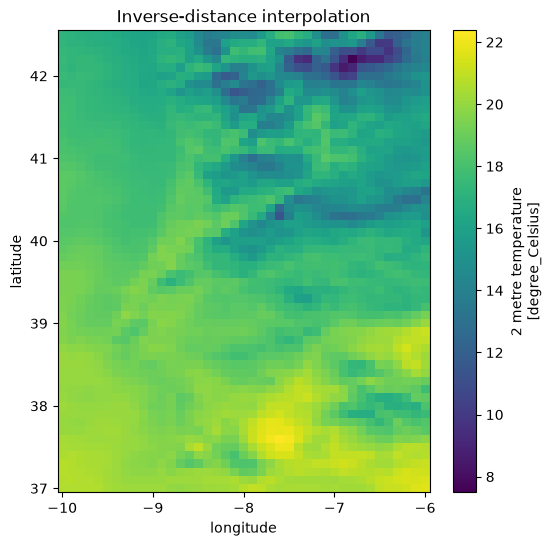

In [11]:
uxfield = ux.UxDataArray(field.drop_indexes(("latitude", "longitude")).rename(cell="n_face"), uxgrid=uxgrid)
target_mesh = ux.Grid.from_structured(lon=target.longitude.values, lat=target.latitude.values)
interpolated = uxfield.remap.inverse_distance_weighted(target_mesh, k=4)
smooth = xr.DataArray(
    interpolated.values.reshape(target.sizes["latitude"], target.sizes["longitude"]),
    dims=("latitude", "longitude"), coords=target.coords, attrs=field.attrs,
)
smooth.plot(x="longitude", y="latitude", figsize=(6, 6), cmap="viridis", center=False)
plt.title("Inverse-distance interpolation");

### 10. Find cells sharing an edge — Xugrid

Xugrid derives face-to-face connectivity from the stored face-node topology. Its sparse connectivity matrix gives the direct neighbours of the Lisbon cell selected in step 1.

In [12]:
neighbours = xgrid.face_face_connectivity.getrow(point.cell.item()).indices
field.isel(cell=neighbours).to_dataframe()[["latitude", "longitude", "temperature_2m"]]

,latitude,longitude,temperature_2m
cell,,,
481032,38.746048,-9.175564,19.125
481038,38.753891,-9.064522,19.375
481191,38.668335,-9.107323,19.375


### Tell us what felt awkward

- Which patterns would you use, and which steps would you change?
- Would a stored `cell_area` coordinate simplify your work?
- How well does a separate `mesh/` group work with your preferred tools?